# 乳癌資料庫預測SVM分類
>使用scikit-learn 機器學習套件裡的SVR演算法

* (一)引入函式庫及內建乳癌資料集<br>
引入之函式庫如下<br>
sklearn.datasets: 用來匯入內建之乳癌資料集`datasets.load_breast_cancer()`<br>
sklearn.SVR: 支持向量機回歸分析之演算法<br>
matplotlib.pyplot: 用來繪製影像

In [101]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn import svm
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

## Step1. 下載資料

In [103]:
breast_cancer=datasets.load_breast_cancer()

In [105]:
features=breast_cancer.data
target=breast_cancer.target
print(breast_cancer.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [107]:
print(breast_cancer.feature_names)

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [ ]:
'''
資料集的核心其實只有 10 種基礎細胞核特徵，但針對每種特徵分別計算了其平均值（Mean）、
標準誤差（Standard Error, SE） 及 最大值/最差值（Worst），因此衍生出 10 × 3 = 30 個欄位。

資料集內包含十種基礎細胞核特徵定義：
1. radius（半徑）： 從中心點到邊界點的平均距離。
2. texture（紋理）： 灰階值的標準差（反應表面外觀的均勻度）。
3. perimeter（周長）： 細胞核邊界的長度。
4. area（面積）： 細胞核的實體大小。
5. smoothness（平滑度）： 半徑長度的局部變化程度。
6. compactness（緊湊度）： 計算公式為 \(\frac{\text{周長}^2}{\text{面積}} - 1.0\)，數值越小形狀越接近圓形。
7. concavity（凹度）： 輪廓凹陷部分的嚴重程度。
8. concave points（凹點數）： 輪廓凹陷部分的數量。
9. symmetry（對稱性）： 細胞核形狀的對稱程度。
10. fractal dimension（分形維度）： 利用「邊界近似法」測量細胞核邊界的複雜度。
'''

In [109]:
'''
target（診斷結果）：
• 0 代表 Malignant（惡性腫瘤）
• 1 代表 Benign（良性腫瘤）
'''
print(breast_cancer.target_names)

['malignant' 'benign']


In [111]:
# 1. 將特徵數據轉換為 Pandas DataFrame，並加上欄位名稱
df = pd.DataFrame(breast_cancer.data, columns=breast_cancer.feature_names)

# 2. 把目標分類（0=惡性, 1=良性）加到表格最後一欄
df['target'] = breast_cancer.target

# 3. 查看資料集的前 5 筆數據與所有欄位
print("資料集形狀 (列, 行):", df.shape)
df.head()

資料集形狀 (列, 行): (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [113]:
features

array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
        1.189e-01],
       [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
        8.902e-02],
       [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
        8.758e-02],
       ...,
       [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
        7.820e-02],
       [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
        1.240e-01],
       [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
        7.039e-02]], shape=(569, 30))

In [115]:
target_names=breast_cancer.target_names
labels=target_names[target]

In [117]:
labels

array(['malignant', 'malignant', 'malignant', 'malignant', 'malignant',
       'malignant', 'malignant', 'malignant', 'malignant', 'malignant',
       'malignant', 'malignant', 'malignant', 'malignant', 'malignant',
       'malignant', 'malignant', 'malignant', 'malignant', 'benign',
       'benign', 'benign', 'malignant', 'malignant', 'malignant',
       'malignant', 'malignant', 'malignant', 'malignant', 'malignant',
       'malignant', 'malignant', 'malignant', 'malignant', 'malignant',
       'malignant', 'malignant', 'benign', 'malignant', 'malignant',
       'malignant', 'malignant', 'malignant', 'malignant', 'malignant',
       'malignant', 'benign', 'malignant', 'benign', 'benign', 'benign',
       'benign', 'benign', 'malignant', 'malignant', 'benign',
       'malignant', 'malignant', 'benign', 'benign', 'benign', 'benign',
       'malignant', 'benign', 'malignant', 'malignant', 'benign',
       'benign', 'benign', 'benign', 'malignant', 'benign', 'malignant',
       'malignan

In [119]:
for idx, name in enumerate(breast_cancer.feature_names):
    print(f"Index {idx}: {name}")

Index 0: mean radius
Index 1: mean texture
Index 2: mean perimeter
Index 3: mean area
Index 4: mean smoothness
Index 5: mean compactness
Index 6: mean concavity
Index 7: mean concave points
Index 8: mean symmetry
Index 9: mean fractal dimension
Index 10: radius error
Index 11: texture error
Index 12: perimeter error
Index 13: area error
Index 14: smoothness error
Index 15: compactness error
Index 16: concavity error
Index 17: concave points error
Index 18: symmetry error
Index 19: fractal dimension error
Index 20: worst radius
Index 21: worst texture
Index 22: worst perimeter
Index 23: worst area
Index 24: worst smoothness
Index 25: worst compactness
Index 26: worst concavity
Index 27: worst concave points
Index 28: worst symmetry
Index 29: worst fractal dimension


In [ ]:
'''
根據機器學習與 SHAP 值的多項實務評估，以下特徵對於區分惡性 (Malignant) 或良性 (Benign) 腫瘤最具決定性：
1. worst concave points（最大凹點數）： 細胞核邊緣凹陷點的最大值。在多數模型中，這常被評為最重要（Top 1）特徵，因為惡性細胞通常形狀極不規則。
2. worst perimeter / worst area / worst radius（最大周長/面積/半徑）： 這三個特徵高度正相關。當腫瘤細胞各項幾何尺寸的最大值偏大時，是惡性腫瘤極強烈的訊號。
3. mean concavity / worst concavity（平均/最大 凹度）： 細胞核邊緣的凹陷嚴重程度。惡性細胞核的邊緣往往比良性細胞更凹凸不平。
'''

In [121]:
#1 代表 benign（良性腫瘤）
benign_area=features[labels=='benign',22]
benign_concavity=features[labels=='benign',27]
benign=np.c_[benign_area,benign_concavity]
benign

array([[9.970e+01, 1.288e-01],
       [9.609e+01, 7.283e-02],
       [6.513e+01, 6.227e-02],
       [8.446e+01, 5.013e-02],
       [5.726e+01, 2.564e-02],
       [8.988e+01, 6.548e-02],
       [9.900e+01, 1.282e-01],
       [8.298e+01, 3.715e-02],
       [9.608e+01, 8.586e-02],
       [8.367e+01, 6.296e-02],
       [8.181e+01, 6.316e-02],
       [9.024e+01, 1.111e-02],
       [5.990e+01, 4.419e-02],
       [6.986e+01, 2.579e-02],
       [6.206e+01, 2.778e-02],
       [6.559e+01, 5.087e-02],
       [6.703e+01, 6.517e-02],
       [7.800e+01, 6.961e-02],
       [6.550e+01, 1.750e-01],
       [8.567e+01, 5.882e-02],
       [6.256e+01, 4.786e-02],
       [8.971e+01, 8.660e-02],
       [9.136e+01, 7.407e-02],
       [9.188e+01, 7.926e-02],
       [8.453e+01, 6.127e-02],
       [9.666e+01, 1.708e-01],
       [8.778e+01, 7.632e-02],
       [9.146e+01, 1.205e-01],
       [1.094e+02, 1.397e-01],
       [1.029e+02, 6.946e-02],
       [1.045e+02, 1.001e-01],
       [9.759e+01, 7.911e-02],
       [

In [123]:
#0 代表 Malignant（惡性腫瘤）
malignant_area=features[labels=='malignant',23]
malignant_concavity=features[labels=='malignant',26]
malignant=np.c_[malignant_area,malignant_concavity]
malignant

array([[2.019e+03, 7.119e-01],
       [1.956e+03, 2.416e-01],
       [1.709e+03, 4.504e-01],
       [5.677e+02, 6.869e-01],
       [1.575e+03, 4.000e-01],
       [7.416e+02, 5.355e-01],
       [1.606e+03, 3.784e-01],
       [8.970e+02, 2.678e-01],
       [7.393e+02, 5.390e-01],
       [7.114e+02, 1.105e+00],
       [1.150e+03, 1.459e-01],
       [1.299e+03, 3.965e-01],
       [1.332e+03, 3.639e-01],
       [8.765e+02, 2.322e-01],
       [6.977e+02, 6.943e-01],
       [9.432e+02, 7.026e-01],
       [1.138e+03, 2.914e-01],
       [1.315e+03, 4.784e-01],
       [2.398e+03, 5.372e-01],
       [9.809e+02, 6.305e-01],
       [2.615e+03, 3.155e-01],
       [2.215e+03, 4.695e-01],
       [1.461e+03, 3.853e-01],
       [8.969e+02, 5.539e-01],
       [1.403e+03, 3.446e-01],
       [1.269e+03, 6.335e-01],
       [1.227e+03, 2.489e-01],
       [1.670e+03, 6.133e-01],
       [8.887e+02, 6.956e-01],
       [1.344e+03, 5.588e-01],
       [1.813e+03, 6.091e-01],
       [1.261e+03, 5.274e-01],
       [

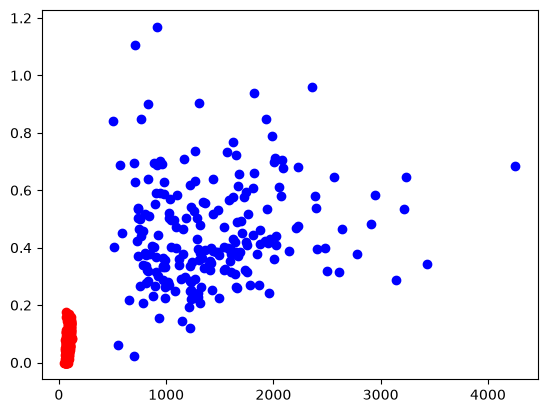

In [125]:
plt.scatter(benign[:,0],benign[:,1],color='red')
plt.scatter(malignant[:,0],malignant[:,1],color='blue')

## Step2. 區分訓練集與測試集

In [127]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [129]:
print(f"原始特徵總數: {breast_cancer.data.shape[1]}")

原始特徵總數: 30


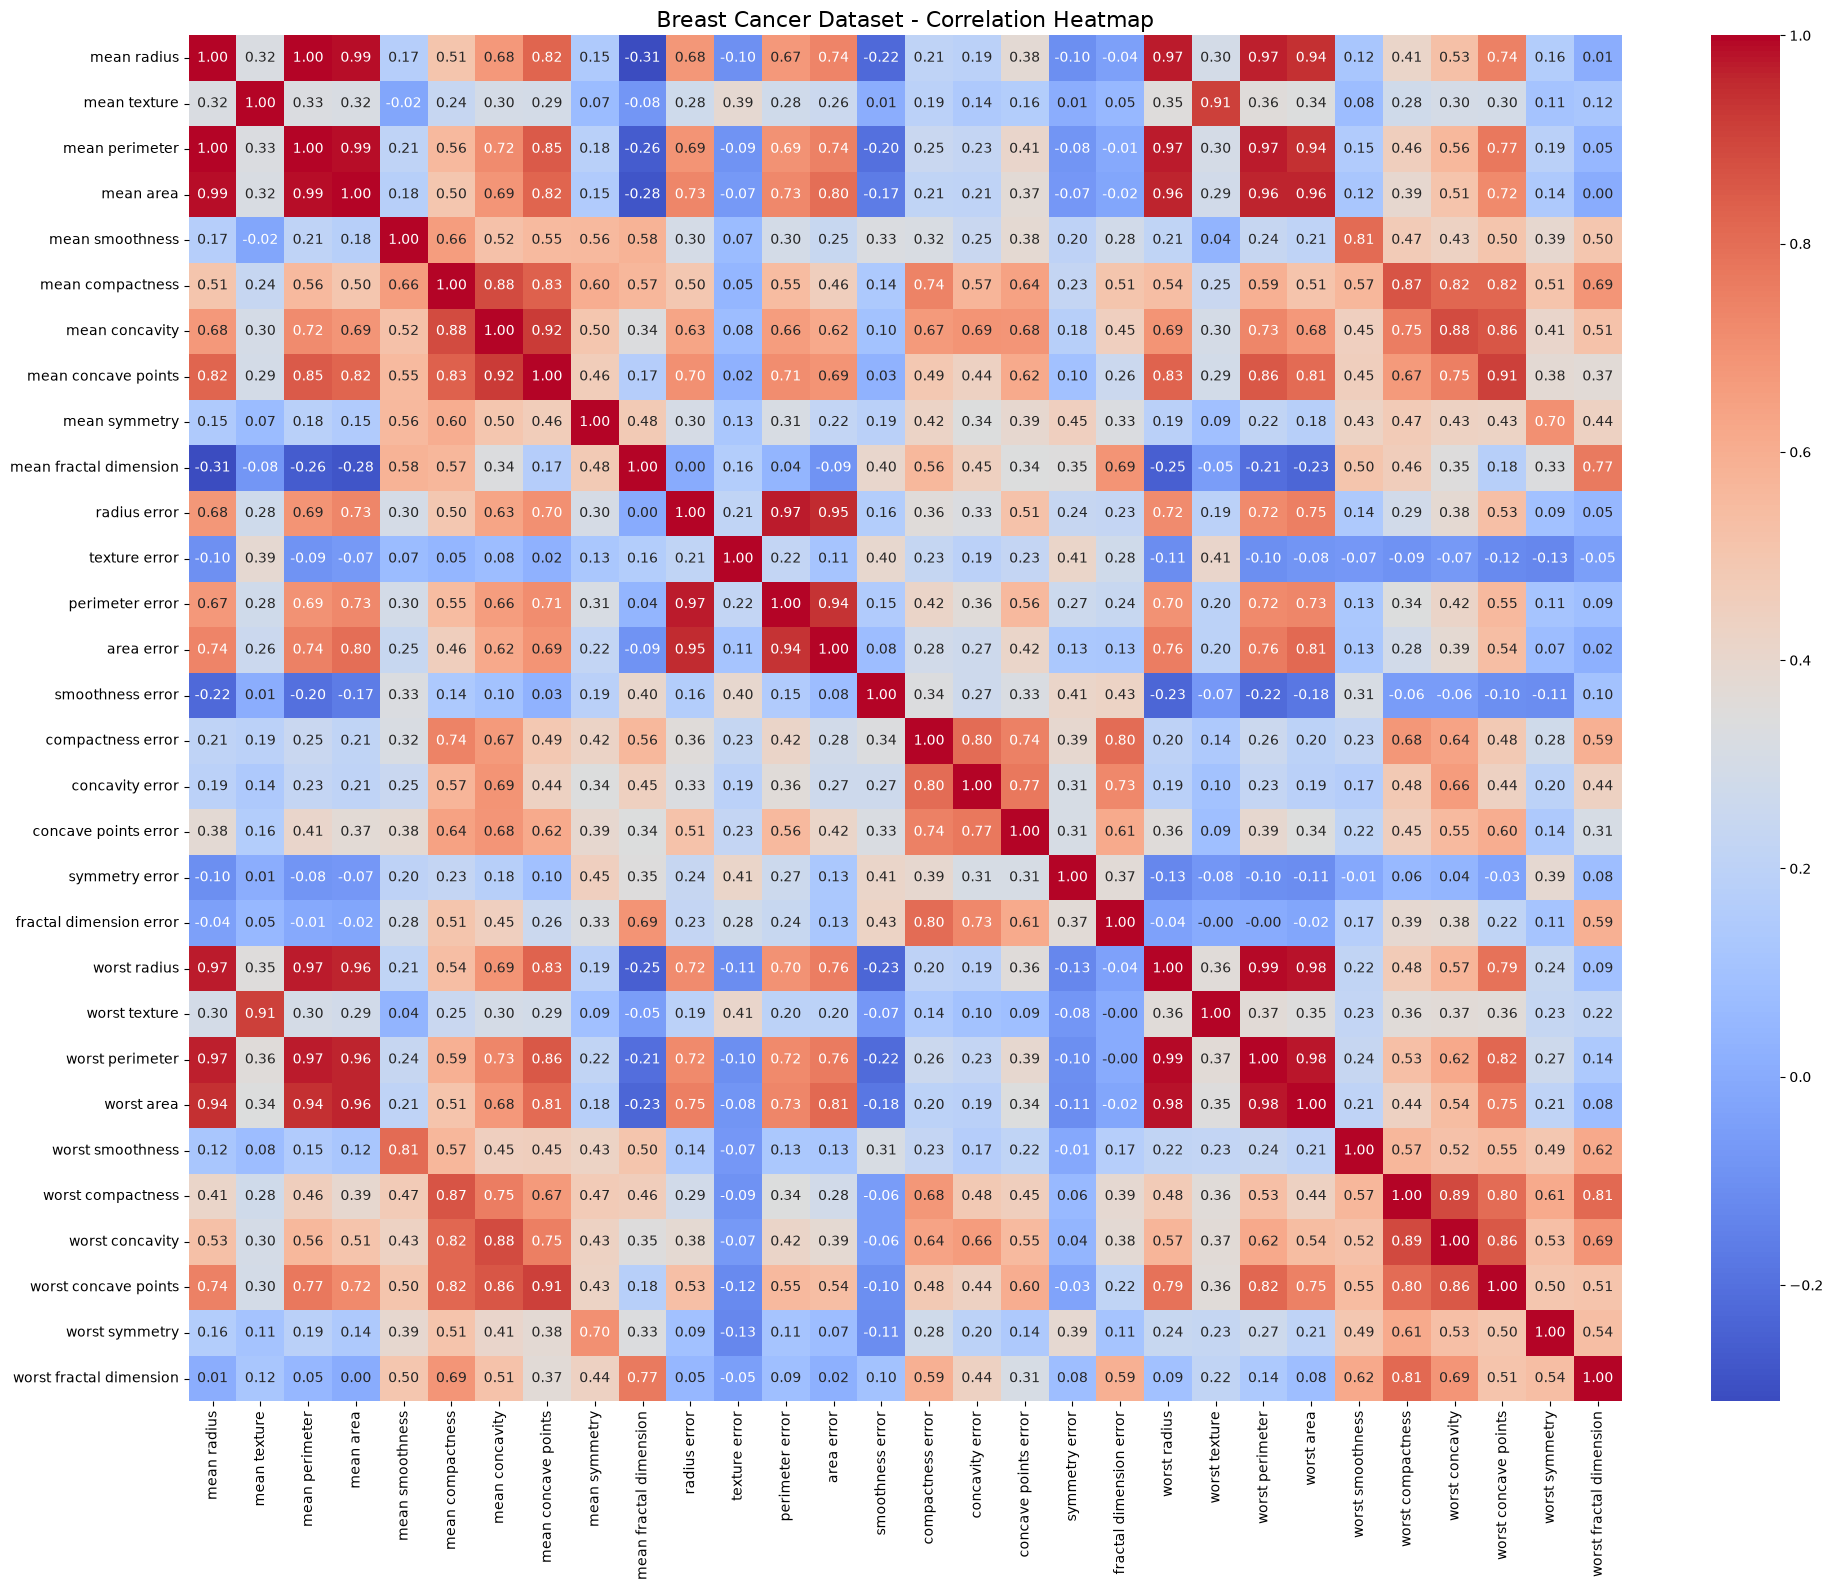

In [131]:
# -------------------------------------------------------------
# 1. 繪製相關性熱圖 (Correlation Heatmap)
# -------------------------------------------------------------

plt.figure(figsize=(20, 16))
# 計算特徵間的相關係數矩陣
corr_matrix = df.iloc[:, 0:30].corr()

# 繪製 Heatmap
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Breast Cancer Dataset - Correlation Heatmap", fontsize=16)
plt.tight_layout()
plt.show()

In [133]:
# -------------------------------------------------------------
# 2. 自動識別並過濾 > 0.9 的特徵群（依規則優先保留 'worst' 特徵）
# -------------------------------------------------------------
# 定義高相關的群組（依據矩陣運算，將高度重疊的特徵歸類）
# 核心邏輯：在這些大於 0.9 的群組中，我們手動選擇一個代表性的 'worst' 特徵，其餘刪除
drop_features = [
    # 尺寸群組 (Size/Shape): 半徑、周長、面積高度正相關，我們只保留 worst radius
    'mean radius', 'mean perimeter', 'mean area', 
    'radius error', 'perimeter error', 'area error', 
    'worst perimeter', 'worst area',
    
    # 紋理群組 (Texture): mean 與 worst 高度相關，只保留 worst texture
    'mean texture',
    
    # 輪廓不規則群組 (Irregularity): 緊湊度、凹度、凹點數高度相關，只保留 worst concave points
    'mean compactness', 'mean concavity', 'mean concave points',
    'worst compactness', 'worst concavity'
]

In [135]:
# 刪除高度相關的特徵，留下過濾後的精簡特徵集
df_reduced = df.drop(columns=drop_features)
X_reduced = df_reduced.drop(columns=['target'])
y_reduced = df_reduced['target']

print(f"篩選後保留的特徵數量: {X_reduced.shape[1]}")
print("保留的特徵包含:", list(X_reduced.columns))

篩選後保留的特徵數量: 16
保留的特徵包含: ['mean smoothness', 'mean symmetry', 'mean fractal dimension', 'texture error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst smoothness', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [137]:
#載入訓練組及測試組分組套件
from sklearn.model_selection import train_test_split

In [139]:
#建立feature資料集(選取survived以外所有欄位)與target資料集(survived)
X = X_reduced
y = y_reduced

In [141]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=40)

## Step3. 建模

In [167]:
clf=svm.SVC(kernel='poly',gamma='auto',C=100*0.5)
clf.fit(X_train,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",50.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'poly'
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'auto'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


## Step4. 預測

```

```


In [169]:
clf.predict(X_test)

array([1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0,
       1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0,
       1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0])

## Step5. 準確度分析

In [171]:
print(clf.score(X_train,y_train))
print(clf.score(X_test, y_test))

0.9773869346733668
0.9415204678362573
